In [83]:

# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
import zipfile

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [85]:
from google.colab import files
uploaded = files.upload()

Saving archive (1).zip to archive (1) (2).zip


In [86]:
df=pd.read_csv('/content/archive (1).zip')
df.head()

,id,asins,brand,categories,colors,dateAdded,dateUpdated,dimension,ean,keys,...,reviews.rating,reviews.sourceURLs,reviews.text,reviews.title,reviews.userCity,reviews.userProvince,reviews.username,sizes,upc,weight
0,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I initially had trouble deciding between the p...,"Paperwhite voyage, no regrets!",NaN,NaN,Cristina M,NaN,NaN,205 grams
1,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,Allow me to preface this with a little history...,One Simply Could Not Ask For More,NaN,NaN,Ricky,NaN,NaN,205 grams
2,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,4.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I am enjoying it so far. Great for reading. Ha...,Great for those that just want an e-reader,NaN,NaN,Tedd Gardiner,NaN,NaN,205 grams
3,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I bought one of the first Paperwhites and have...,Love / Hate relationship,NaN,NaN,Dougal,NaN,NaN,205 grams
4,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I have to say upfront - I don't like coroporat...,I LOVE IT,NaN,NaN,Miljan David Tanic,NaN,NaN,205 grams


In [87]:
df.shape

(1597, 27)

In [88]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1597 entries, 0 to 1596
Data columns (total 27 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    1597 non-null   object 
 1   asins                 1597 non-null   object 
 2   brand                 1597 non-null   object 
 3   categories            1597 non-null   object 
 4   colors                774 non-null    object 
 5   dateAdded             1597 non-null   object 
 6   dateUpdated           1597 non-null   object 
 7   dimension             565 non-null    object 
 8   ean                   898 non-null    float64
 9   keys                  1597 non-null   object 
 10  manufacturer          965 non-null    object 
 11  manufacturerNumber    902 non-null    object 
 12  name                  1597 non-null   object 
 13  prices                1597 non-null   object 
 14  reviews.date          1217 non-null   object 
 15  reviews.doRecommend  

In [89]:
df.isnull().sum()

,0
id,0
asins,0
brand,0
categories,0
colors,823
dateAdded,0
dateUpdated,0
dimension,1032
ean,699
keys,0


In [90]:
df['reviews.rating'].value_counts().sort_index()

,count
reviews.rating,
1.0,42
2.0,34
3.0,124
4.0,236
5.0,741


In [91]:
df = df.dropna(subset=['reviews.rating'])

In [92]:
df.isnull().sum()

,0
id,0
asins,0
brand,0
categories,0
colors,508
dateAdded,0
dateUpdated,0
dimension,620
ean,484
keys,0


In [93]:
df.shape

(1177, 27)

In [94]:
df['reviews.rating'].value_counts().sort_index()

,count
reviews.rating,
1.0,42
2.0,34
3.0,124
4.0,236
5.0,741


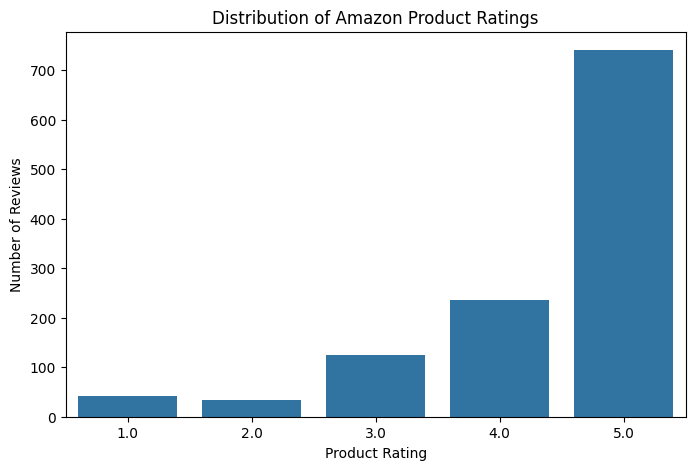

In [95]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='reviews.rating')
plt.title('Distribution of Amazon Product Ratings')
plt.xlabel('Product Rating')
plt.ylabel('Number of Reviews')
plt.show()

In [96]:
y = df['reviews.rating']

In [97]:
X = df.drop(columns=[
    'reviews.rating',
    'reviews.doRecommend',
    'reviews.numHelpful'
], errors='ignore')

In [98]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1177, 24)
Target shape: (1177,)


In [99]:
print(y.head(10))

0     5.0
1     5.0
2     4.0
3     5.0
4     5.0
13    4.0
14    5.0
15    5.0
16    4.0
17    5.0
Name: reviews.rating, dtype: float64


In [100]:

print(y.value_counts().sort_index())

reviews.rating
1.0     42
2.0     34
3.0    124
4.0    236
5.0    741
Name: count, dtype: int64


In [101]:
print("Numerical columns:")
print(X.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical columns:")
print(X.select_dtypes(include=['object']).columns.tolist())

Numerical columns:
['ean', 'reviews.userCity', 'reviews.userProvince', 'sizes', 'upc']

Categorical columns:
['id', 'asins', 'brand', 'categories', 'colors', 'dateAdded', 'dateUpdated', 'dimension', 'keys', 'manufacturer', 'manufacturerNumber', 'name', 'prices', 'reviews.date', 'reviews.sourceURLs', 'reviews.text', 'reviews.title', 'reviews.username', 'weight']


In [102]:
missing_values = X.isnull().sum()

print(missing_values[missing_values > 0].sort_values(ascending=False))

sizes                   1177
reviews.userProvince    1177
reviews.userCity        1177
dimension                620
weight                   525
colors                   508
ean                      484
upc                      484
manufacturerNumber       479
manufacturer             451
reviews.date             217
dtype: int64


In [103]:
for col in numerical_cols:
    X[col] = X[col].fillna(X[col].median())

for col in categorical_cols:
    X[col] = X[col].fillna('Unknown')

In [104]:
print(X.isnull().sum().sum())

1177


In [105]:
X = X.drop(columns=['sizes'], errors='ignore')
if 'sizes' in numerical_cols:
    numerical_cols.remove('sizes')

In [106]:
for col in numerical_cols:
    X[col] = X[col].fillna(X[col].median())

for col in categorical_cols:
    X[col] = X[col].fillna('Unknown')

In [107]:
print(X.isnull().sum().sum())

0


In [108]:
print(X.shape)
print(X.head())

(1177, 23)
                     id       asins   brand                  categories  \
0  AVpe7AsMilAPnD_xQ78G  B00QJDU3KY  Amazon  Amazon Devices,mazon.co.uk   
1  AVpe7AsMilAPnD_xQ78G  B00QJDU3KY  Amazon  Amazon Devices,mazon.co.uk   
2  AVpe7AsMilAPnD_xQ78G  B00QJDU3KY  Amazon  Amazon Devices,mazon.co.uk   
3  AVpe7AsMilAPnD_xQ78G  B00QJDU3KY  Amazon  Amazon Devices,mazon.co.uk   
4  AVpe7AsMilAPnD_xQ78G  B00QJDU3KY  Amazon  Amazon Devices,mazon.co.uk   

    colors             dateAdded           dateUpdated  \
0  Unknown  2016-03-08T20:21:53Z  2017-07-18T23:52:58Z   
1  Unknown  2016-03-08T20:21:53Z  2017-07-18T23:52:58Z   
2  Unknown  2016-03-08T20:21:53Z  2017-07-18T23:52:58Z   
3  Unknown  2016-03-08T20:21:53Z  2017-07-18T23:52:58Z   
4  Unknown  2016-03-08T20:21:53Z  2017-07-18T23:52:58Z   

                  dimension           ean                         keys  ...  \
0  169 mm x 117 mm x 9.1 mm  8.416670e+11  kindlepaperwhite/b00qjdu3ky  ...   
1  169 mm x 117 mm x 9.1 mm  8.

In [109]:
from sklearn.model_selection import train_test_split

In [110]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [111]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (941, 23)
Testing data: (236, 23)
Training target: (941,)
Testing target: (236,)


In [112]:
from sklearn.ensemble import RandomForestClassifier

In [113]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [115]:
# Apply One-Hot Encoding to categorical columns to make them numerical
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# Split the newly encoded dataset into training and testing sets
X_train_enc, X_test_enc, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# Train the Random Forest model with the encoded numerical features
model.fit(X_train_enc, y_train)
print("Model trained successfully after One-Hot Encoding categorical variables!")

Model trained successfully after One-Hot Encoding categorical variables!


In [117]:
# Predict using the encoded test features
y_pred = model.predict(X_test_enc)

In [118]:
comparison = pd.DataFrame({
    'Actual Rating': y_test,
    'Predicted Rating': y_pred
})

print(comparison.head(10))

      Actual Rating  Predicted Rating
1142            5.0               5.0
1137            4.0               5.0
959             5.0               5.0
543             5.0               5.0
463             1.0               5.0
957             5.0               5.0
1006            2.0               5.0
1572            3.0               1.0
1293            4.0               5.0
691             5.0               5.0


In [119]:
from sklearn.metrics import accuracy_score

In [120]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 67.37288135593221 %


In [121]:
from sklearn.metrics import confusion_matrix

In [122]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[  0   0   0   1   7]
 [  1   0   0   1   5]
 [  1   0   8   1  15]
 [  0   0   0   5  42]
 [  1   0   0   2 146]]


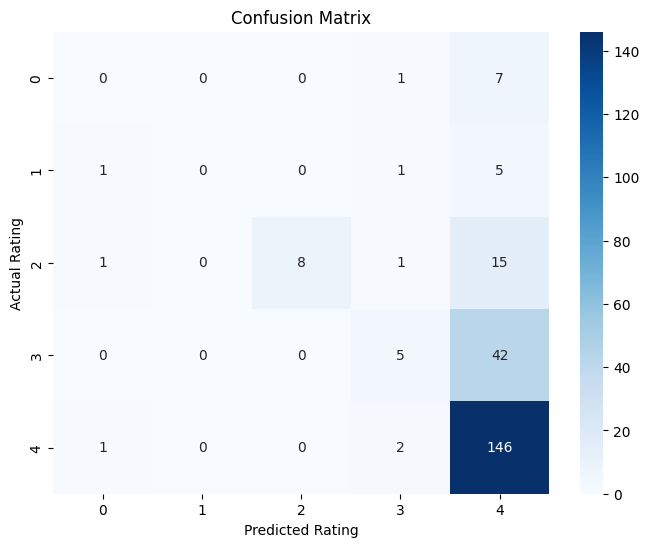

In [123]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Rating')
plt.ylabel('Actual Rating')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
from sklearn.metrics import classification_report

In [ ]:
print(classification_report(y_test, y_pred))

In [ ]:
print(classification_report(y_test, y_pred))

In [ ]:
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance.head(10))

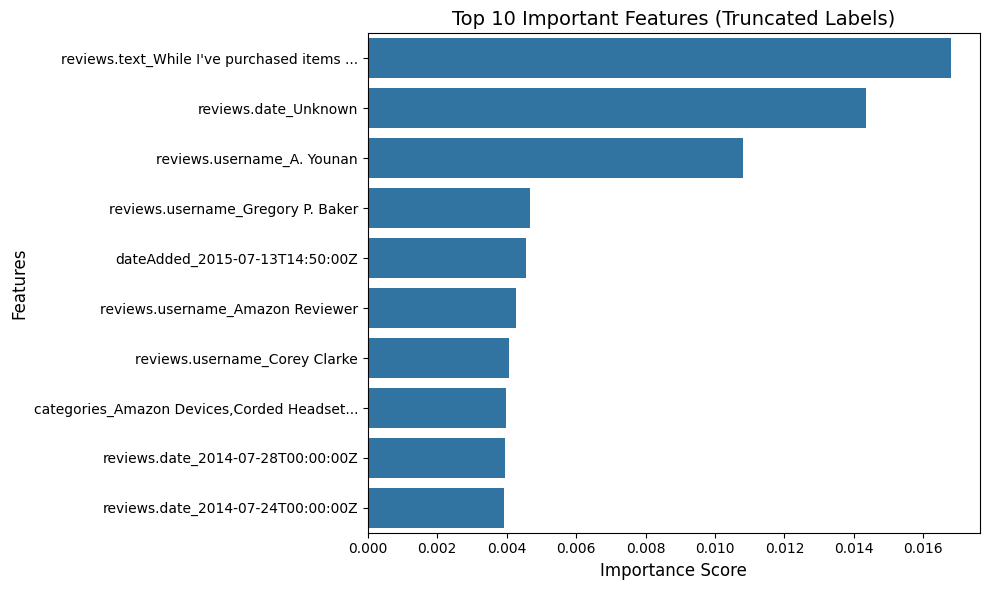

In [124]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a copy of the top 10 features for plotting
plot_data = importance.head(10).copy()

# Helper function to truncate very long dummy-variable feature names
def truncate_label(label, max_len=40):
    if len(str(label)) > max_len:
        return str(label)[:max_len] + '...'
    return str(label)

# Apply truncation to make y-axis labels readable
plot_data['Clean_Feature'] = plot_data['Feature'].apply(lambda x: truncate_label(x))

# Plot again with truncated labels
plt.figure(figsize=(10, 6))
sns.barplot(
    data=plot_data,
    x='Importance',
    y='Clean_Feature'
)

plt.title('Top 10 Important Features (Truncated Labels)', fontsize=14)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)

plt.tight_layout()  # This will now work perfectly since the labels are of reasonable size
plt.show()

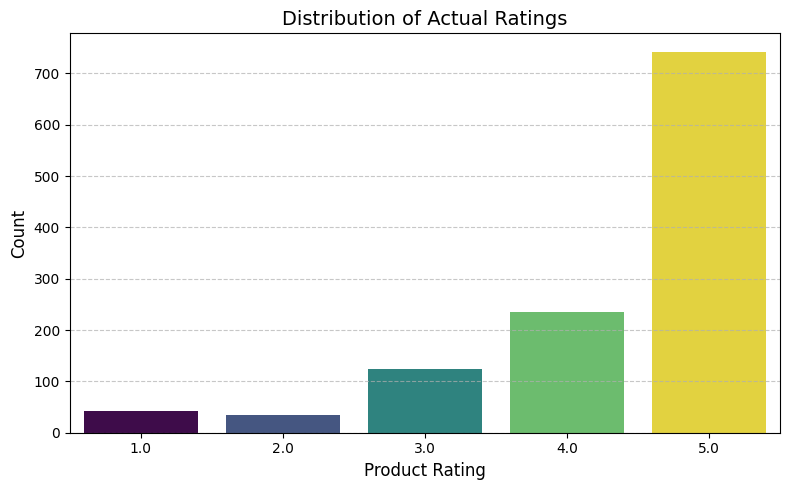

In [125]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a countplot to show the distribution of actual ratings
plt.figure(figsize=(8, 5))
sns.countplot(x=y, hue=y, palette='viridis', legend=False)
plt.title('Distribution of Actual Ratings', fontsize=14)
plt.xlabel('Product Rating', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [126]:
print("Amazon Product Rating Prediction")
print("Algorithm: Random Forest Classification")
print("Total Records:", len(df))
print("Number of Features:", X.shape[1])
print("Model Accuracy:", round(accuracy * 100, 2), "%")

Amazon Product Rating Prediction
Algorithm: Random Forest Classification
Total Records: 1177
Number of Features: 23
Model Accuracy: 67.37 %
